# P2: GloVe embeddings on PAWS (exploration)

What the frozen GloVe 2024 50d vectors can and cannot tell apart on PAWS. Exploration only; the experiments are in `scripts/08..13`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from paws.config import P2Config
from paws.data import load_pairs, split_pair
from paws.embeddings import PairTokenizer, load_embeddings
from paws.error_features import pair_features

cfg = P2Config()
emb = load_embeddings(cfg)
tokenizer = PairTokenizer(cfg, emb)
pairs = load_pairs(cfg)
vectors = emb.vectors[: len(emb.vocab)]  # without the appended [SEP] row
unit = vectors / np.maximum(np.linalg.norm(vectors, axis=1, keepdims=True), 1e-8)

## Nearest neighbours of words PAWS swaps

PAWS swaps entities (places, names, dates) and reorders clauses. If a swapped word's neighbours are words of the same type, swapping two of them barely moves a pooled sentence vector.

In [2]:
def neighbours(word, n=8):
    scores = unit @ unit[emb.vocab.index(word)]
    best = np.argsort(-scores)[1 : n + 1]
    return [(emb.vocab.word(i), round(float(scores[i]), 2)) for i in best]

for word in ["paris", "london", "germany", "john", "january", "north", "before", "after", "first", "however"]:
    print(f"{word:10s}", neighbours(word))

paris      [('france', 0.83), ('brussels', 0.83), ('french', 0.81), ('amsterdam', 0.8), ('london', 0.78), ('vienna', 0.77), ('berlin', 0.75), ('opened', 0.74)]
london     [('sydney', 0.85), ('opened', 0.84), ('melbourne', 0.82), ('at', 0.81), ('dublin', 0.8), ('british', 0.79), ('edinburgh', 0.78), ('paris', 0.78)]
germany    [('german', 0.9), ('austria', 0.88), ('switzerland', 0.85), ('europe', 0.83), ('belgium', 0.82), ('france', 0.82), ('austrian', 0.82), ('european', 0.82)]
john       [('james', 0.93), ('thomas', 0.91), ('william', 0.9), ('henry', 0.89), ('charles', 0.88), ('george', 0.88), ('robert', 0.86), ('smith', 0.86)]
january    [('december', 0.99), ('september', 0.99), ('february', 0.99), ('october', 0.99), ('november', 0.99), ('june', 0.99), ('august', 0.99), ('april', 0.99)]


north      [('east', 0.96), ('south', 0.95), ('west', 0.95), ('northern', 0.91), ('western', 0.89), ('southern', 0.89), ('eastern', 0.89), ('northwest', 0.88)]
before     [('after', 0.96), ('when', 0.95), ('went', 0.94), ('then', 0.94), ('took', 0.94), ('again', 0.93), ('came', 0.93), ('on', 0.93)]
after      [('before', 0.96), ('took', 0.95), ('came', 0.95), ('when', 0.94), ('went', 0.93), ('last', 0.93), ('ended', 0.92), ('weeks', 0.92)]
first      [('second', 0.95), ('third', 0.93), ('came', 0.92), ('one', 0.91), ('time', 0.91), ('took', 0.91), ('followed', 0.91), ('later', 0.91)]
however    [('although', 0.98), ('though', 0.94), ('may', 0.93), ('also', 0.93), ('as', 0.93), ('both', 0.93), ('this', 0.93), ('.', 0.92)]


## Cosine of the two mean-pooled sentences, by label

Mean pooling ignores word order, so a pair with the same word set gets (almost) the same two vectors whatever its label.

In [3]:
def mean_vector(sentence):
    ids = tokenizer.words.ids(sentence)
    return emb.vectors[ids].mean(axis=0)

def cosine(a, b):
    return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b)))

cos = np.array([cosine(*(mean_vector(s) for s in split_pair(text))) for text, _ in pairs])
labels = np.array([label for _, label in pairs])
same = np.array([pair_features(text, tokenizer)["same_word_set"] == 1.0 for text, _ in pairs])

for name, mask in [("all pairs", np.ones_like(same)), ("same word set", same), ("other", ~same)]:
    for label, label_name in [(0, "different"), (1, "paraphrase")]:
        values = cos[mask & (labels == label)]
        print(f"{name:14s} {label_name:10s} n={len(values):5d} mean cos={values.mean():.4f} median={np.median(values):.4f}")

all pairs      different  n=11191 mean cos=0.9980 median=0.9986
all pairs      paraphrase n= 8809 mean cos=0.9980 median=0.9986
same word set  different  n= 1674 mean cos=0.9996 median=1.0000
same word set  paraphrase n=  952 mean cos=0.9993 median=0.9997
other          different  n= 9517 mean cos=0.9977 median=0.9985
other          paraphrase n= 7857 mean cos=0.9979 median=0.9985


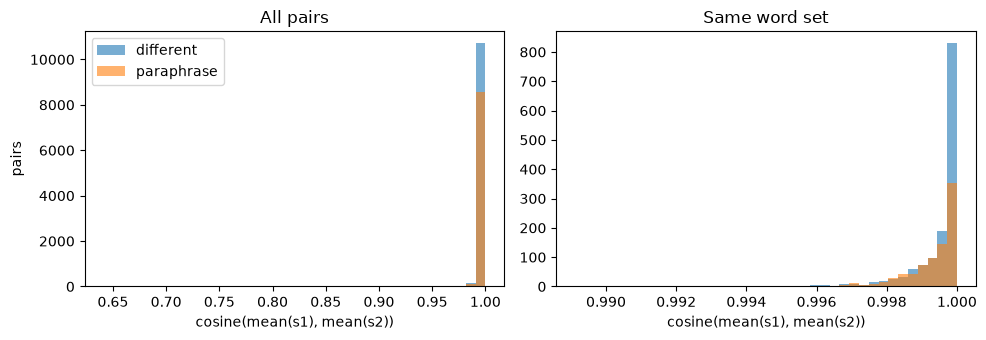

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=False)
for ax, (title, mask) in zip(axes, [("All pairs", np.ones_like(same)), ("Same word set", same)]):
    bins = np.linspace(cos[mask].min(), 1, 40)
    for label, label_name in [(0, "different"), (1, "paraphrase")]:
        ax.hist(cos[mask & (labels == label)], bins=bins, alpha=0.6, label=label_name)
    ax.set_title(title)
    ax.set_xlabel("cosine(mean(s1), mean(s2))")
axes[0].set_ylabel("pairs")
axes[0].legend()
fig.tight_layout()
fig.savefig(cfg.results_dir / "embedding_cosine_by_label.png", dpi=200, bbox_inches="tight")

## Limitations of GloVe for this task

- **Swappable words are neighbours.** Cities, first names, months and compass points have their own type as nearest
  neighbours (january -> december 0.99, john -> james 0.93, north -> east 0.96), so swapping two of them, the core
  PAWS perturbation, barely moves any sentence vector.
- **Opposite relations look the same.** *before* and *after* are each other's nearest neighbour (0.96): a static,
  distributional vector encodes "temporal connective", not the direction that decides the label.
- **Pooled sentences are indistinguishable.** The cosine of the two mean-pooled sentences is 0.998 for both labels,
  with identical distributions; on same-word-set pairs it is 1.000 (median). Mean pooling of GloVe carries no label
  information on PAWS, which is why both pooling systems stay at the majority baseline.
- **One vector per type, uncased, with rare names unknown.** No context, no case, and the rare entities PAWS swaps are
  5.5x more often OOV (`results/p2/coverage.json`); two unknown names both become `<unk>`, so their swap is invisible.
  These limitations sit in the representation, so only an encoder that tracks order *and* compares the sentences
  (siamese LSTM) gets past them.